# Bacterial Aggregate Analysis: step-by-step walkthrough

This notebook runs the same workflow as the scripts in this folder, one step at a time, with a picture after each step:

1. Get the example images
2. Look at one image
3. Find the cell pixels
4. Group touching cells into aggregates (clumps) and measure them
5. Run the whole folder automatically
6. Check the results

The images are a free public dataset of *Staphylococcus aureus* (details and credit in the README). The notebook uses the functions from `analyze_images.py`, so it always matches the scripts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display
from skimage import color, filters

import analyze_images as workflow   # the workflow's own functions and settings


def stretch(image):
    """Brighten an image for display so dim cells are visible."""
    low, high = np.percentile(image, [1, 99.5])
    return np.clip((image - low) / (high - low), 0, 1)

## Step 1: Get the example images

This downloads the dataset from Zenodo (about 17 MB) and puts the 12 images in `data/images`. If the file is already there, it is not downloaded again.

In [2]:
!python download_data.py

Already downloaded: data/saureus.zip
Unpacking...


Done. 12 images are in data/images


Their hand-drawn outlines are in data/hand_drawn_masks


## Step 2: Look at one image

The cells' membranes are stained with a fluorescent dye, so the cells glow, with the membrane brightest. Touching cells form clumps.

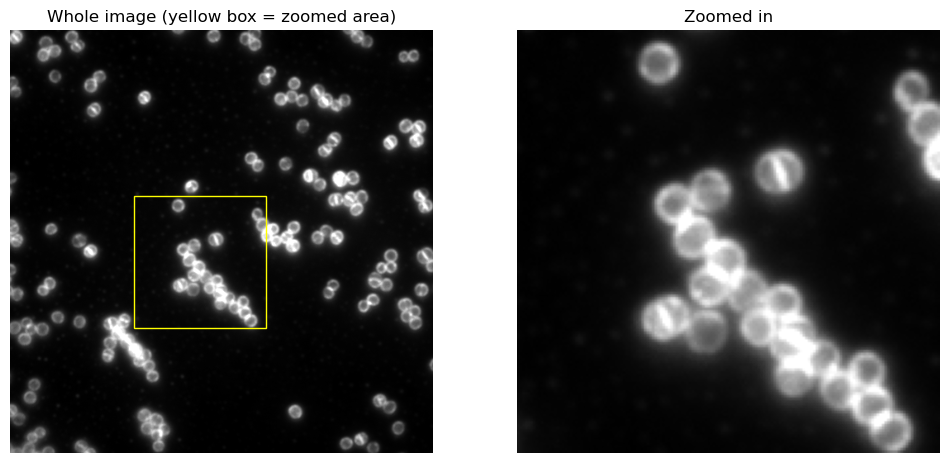

Image size: 512 x 512 pixels
One pixel = 80 nanometres


In [3]:
example = Path("data/images/JE2NileRed_oilp22_PMP_101220_009.tif")
image = workflow.load_image(example)

# A zoomed-in area, so single cells are easy to see.
zoom = (slice(200, 360), slice(150, 310))

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(stretch(image), cmap="gray")
axes[0].add_patch(plt.Rectangle((150, 200), 160, 160, fill=False, color="yellow"))
axes[0].set_title("Whole image (yellow box = zoomed area)")
axes[1].imshow(stretch(image)[zoom], cmap="gray")
axes[1].set_title("Zoomed in")
for ax in axes:
    ax.axis("off")
plt.show()

print(f"Image size: {image.shape[1]} x {image.shape[0]} pixels")
print(f"One pixel = {workflow.PIXEL_SIZE_UM * 1000:.0f} nanometres")

## Step 3: Find the cell pixels

Two steps:

- **3a. Keep the bright pixels.** After a slight blur to smooth out camera noise, the script picks a brightness cut-off automatically (Otsu's method) and keeps every pixel above it. Most cells come out solid.
- **3b. Fill small holes.** A few cells have a dim centre and come out as rings, so holes smaller than one cell are filled. Bigger holes are left alone, because they are real background enclosed by a ring of cells. Tiny specks of noise are also dropped here.

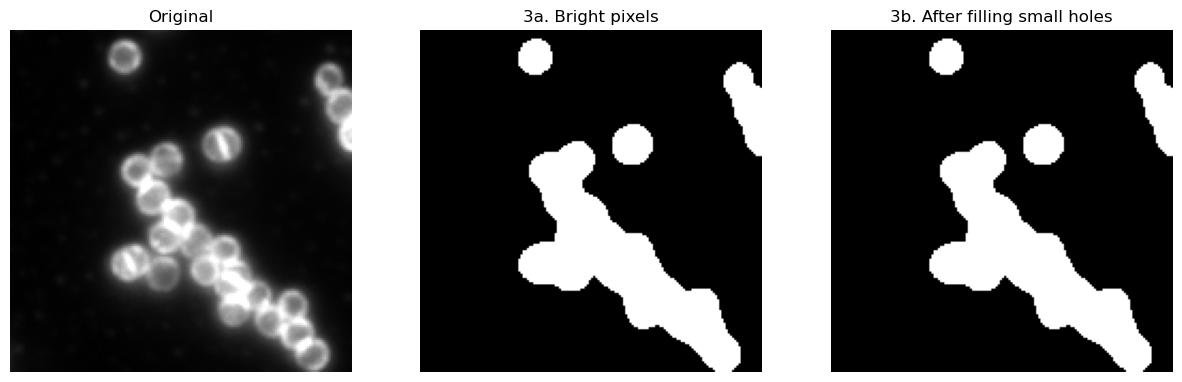

Automatic brightness cut-off: 7350
Cell pixels in this image: 30,784 (11.7% of the image)


In [4]:
# 3a: blur slightly, then keep pixels brighter than the automatic cut-off.
smooth = filters.gaussian(image, sigma=workflow.SMOOTHING, preserve_range=True)
cutoff = filters.threshold_otsu(smooth)
bright = smooth > cutoff

# 3b: the full workflow step (cut-off + fill small holes + drop specks).
is_cell = workflow.find_cell_pixels(image)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(stretch(image)[zoom], cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(bright[zoom], cmap="gray")
axes[1].set_title("3a. Bright pixels")
axes[2].imshow(is_cell[zoom], cmap="gray")
axes[2].set_title("3b. After filling small holes")
for ax in axes:
    ax.axis("off")
plt.show()

print(f"Automatic brightness cut-off: {cutoff:.0f}")
print(f"Cell pixels in this image: {is_cell.sum():,} ({100 * is_cell.mean():.1f}% of the image)")

In the example above, the two pictures look the same, because no cell in that area has a dim centre. Filling only matters for a few cells. Here is one, from another image:

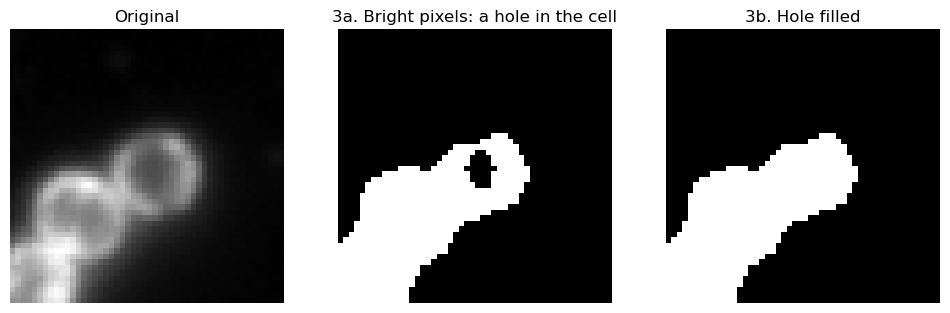

In [5]:
other = workflow.load_image(Path("data/images/JE2NileRed_oilp22_PMP_101220_003.tif"))
other_smooth = filters.gaussian(other, sigma=workflow.SMOOTHING, preserve_range=True)
other_bright = other_smooth > filters.threshold_otsu(other_smooth)
other_filled = workflow.find_cell_pixels(other)

close_up = (slice(331, 381), slice(116, 166))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(stretch(other)[close_up], cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(other_bright[close_up], cmap="gray")
axes[1].set_title("3a. Bright pixels: a hole in the cell")
axes[2].imshow(other_filled[close_up], cmap="gray")
axes[2].set_title("3b. Hole filled")
for ax in axes:
    ax.axis("off")
plt.show()

## Step 4: Group touching cells into aggregates and measure them

Every separate group of touching cell pixels becomes one aggregate, whether it is a single cell or a clump. Each one is measured (size in pixels and in µm², brightness) and sorted by size:

- **Single cell:** up to 2 µm² (a typical cell is about 1.4 µm²)
- **Small clump:** up to 8 µm² (about 2 to 5 cells)
- **Large clump:** above 8 µm²
- **Cut off:** touching the image edge, so its full size is unknown

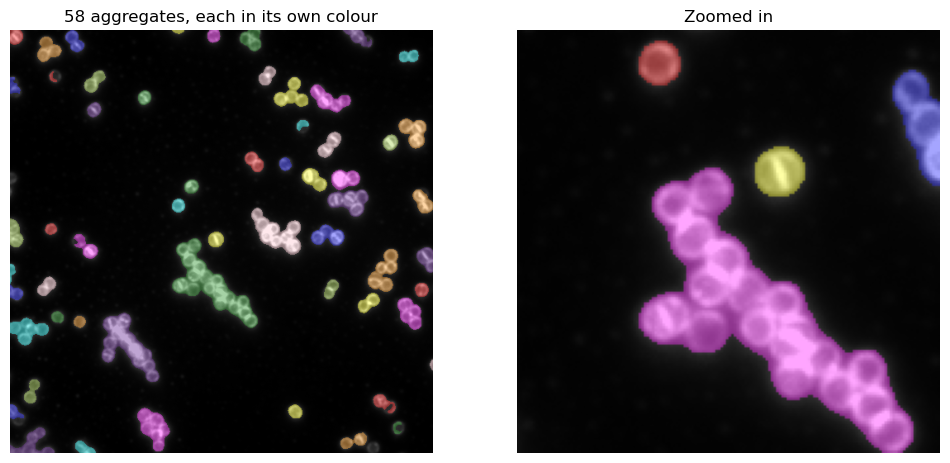

,image,aggregate_id,area_px,area_um2,mean_brightness,touches_edge,size_class
34,JE2NileRed_oilp22_PMP_101220_009.tif,35,3885,24.86,15066.05,False,large_clump
45,JE2NileRed_oilp22_PMP_101220_009.tif,46,2638,16.88,15423.10,False,large_clump
28,JE2NileRed_oilp22_PMP_101220_009.tif,29,1800,11.52,16135.17,False,large_clump
53,JE2NileRed_oilp22_PMP_101220_009.tif,54,1218,7.80,12465.88,False,small_clump
36,JE2NileRed_oilp22_PMP_101220_009.tif,37,1124,7.19,12009.42,False,small_clump


In [6]:
aggregates, rows = workflow.measure_aggregates(is_cell, image, example.name)
table = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(color.label2rgb(aggregates, stretch(image), alpha=0.35, bg_label=0))
axes[0].set_title(f"{len(table)} aggregates, each in its own colour")
axes[1].imshow(color.label2rgb(aggregates[zoom], stretch(image)[zoom], alpha=0.35, bg_label=0))
axes[1].set_title("Zoomed in")
for ax in axes:
    ax.axis("off")
plt.show()

# The five largest aggregates in this image.
table.sort_values("area_um2", ascending=False).head().round(2)

## Step 5: Run the whole folder automatically

The script `analyze_images.py` repeats steps 3 and 4 for every image in `data/images`, with no manual steps, and saves:

- `results/image_summary.csv`: one row per image
- `results/aggregates.csv`: one row per aggregate
- `results/clump_sizes.png`: a chart of the clump sizes in each image
- `results/outlines/`: each image with its aggregates outlined by size class
- `results/run_log.txt`: when it ran, the settings used, and any images skipped

If an image cannot be read, the script skips it, notes it in the log and carries on, so one bad file does not stop an unattended run.

In [7]:
!python analyze_images.py

Analysing 12 images from data/images...


Found 590 aggregates in 12 images.
Tables, chart and outlined images saved in results/


In [8]:
summary = pd.read_csv("results/image_summary.csv")
summary["image"] = summary["image"].str.replace("JE2NileRed_oilp22_PMP_101220_", "image ")
summary.round(2)

,image,cell_pixels,cell_area_um2,percent_covered,aggregate_count,median_aggregate_um2,largest_aggregate_um2,pct_area_single_cell,pct_area_small_clump,pct_area_large_clump,pct_cell_area_cut_off
0,image .tif,59261,379.27,22.61,95,1.79,28.51,22.21,27.13,50.66,22.22
1,image 001.tif,75500,483.20,28.80,80,2.05,36.27,10.65,19.52,69.83,24.84
2,image 002.tif,69351,443.85,26.46,71,2.23,59.13,10.50,27.24,62.26,28.51
3,image 003.tif,11042,70.67,4.21,22,3.56,7.12,10.47,89.53,0.00,4.60
4,image 004.tif,13475,86.24,5.14,31,2.10,8.70,16.31,56.90,26.79,25.10
5,image 005.tif,20492,131.15,7.82,51,1.59,10.33,28.29,52.02,19.68,21.18
6,image 006.tif,17190,110.02,6.56,31,3.61,6.96,8.92,91.08,0.00,19.24
7,image 007.tif,18835,120.54,7.18,39,1.53,21.69,22.89,35.13,41.98,13.36
8,image 008.tif,17050,109.12,6.50,29,3.00,10.46,10.42,66.48,23.10,19.50
9,image 009.tif,30784,197.02,11.74,58,2.24,24.86,14.12,52.67,33.22,18.60


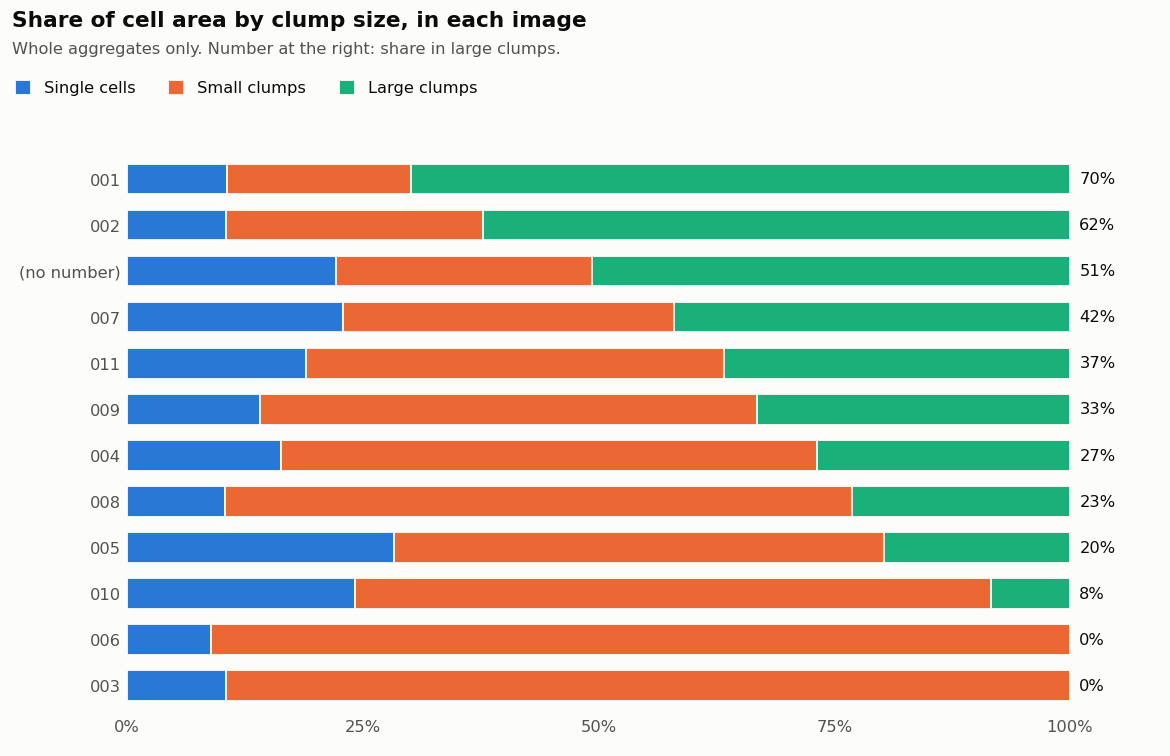

In [9]:
# How the cells are organised in each image.
display(Image("results/clump_sizes.png", width=750))

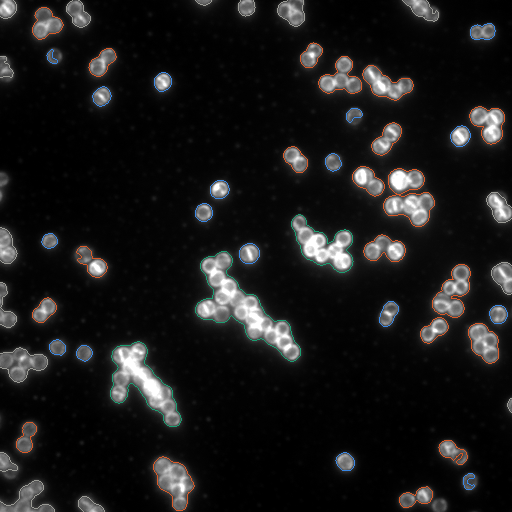

In [10]:
# One of the saved outlined images. Blue = single cell, orange = small clump,
# green = large clump, grey = cut off by the image edge.
display(Image("results/outlines/JE2NileRed_oilp22_PMP_101220_009.png", width=500))

In [11]:
# The record of this run.
print(Path("results/run_log.txt").read_text())

Run finished: 2026-11-01 11:48
Input folder: data/images
Images found: 12
Images analysed: 12
Images skipped: 0
Images with no cells found: 0
Aggregates found: 590

Settings:
  PIXEL_SIZE_UM = 0.08
  SMOOTHING = 1
  MIN_AREA_PX = 30
  MAX_HOLE_PX = 100
  SINGLE_CELL_MAX_UM2 = 2.0
  SMALL_CLUMP_MAX_UM2 = 8.0



## Step 6: Check the results

A workflow that runs without errors can still give wrong numbers, so the results are checked in three ways:

1. **A random sample, reviewed by eye.** Four images are picked at random and shown three ways: the original, what the script found, and the cells a person outlined by hand (the dataset includes these outlines).
2. **A comparison with the hand-drawn outlines** for every image.
3. **A check of the size classes:** how many hand-drawn cells sit inside each aggregate.

To review a different random sample, run `!python check_results.py --seed 7` (any number works).

In [12]:
!python check_results.py

Hand-drawn cell pixels also found by the script: 92% to 99% per image
Hand-drawn cells missed completely: 52 of 1641
Aggregates found by the script: 590  (hand-drawn clumps: 600)
Script aggregates with no hand-drawn cell: 34 cut off by the image edge (not outlined by hand), 1 inside the image (possible false finds)
Aggregates called single cells: 221, of which 88% hold exactly one hand-drawn cell
 size_class  aggregates  median_hand_cells  fewest_hand_cells  most_hand_cells
single_cell         221                1.0                0.0              2.0
small_clump         195                2.0                1.0              7.0
large_clump          47                9.0                5.0             35.0
Random sample to review: JE2NileRed_oilp22_PMP_101220_001, JE2NileRed_oilp22_PMP_101220_002, JE2NileRed_oilp22_PMP_101220_004, JE2NileRed_oilp22_PMP_101220_009


Saved pictures to results/check/random_sample.png


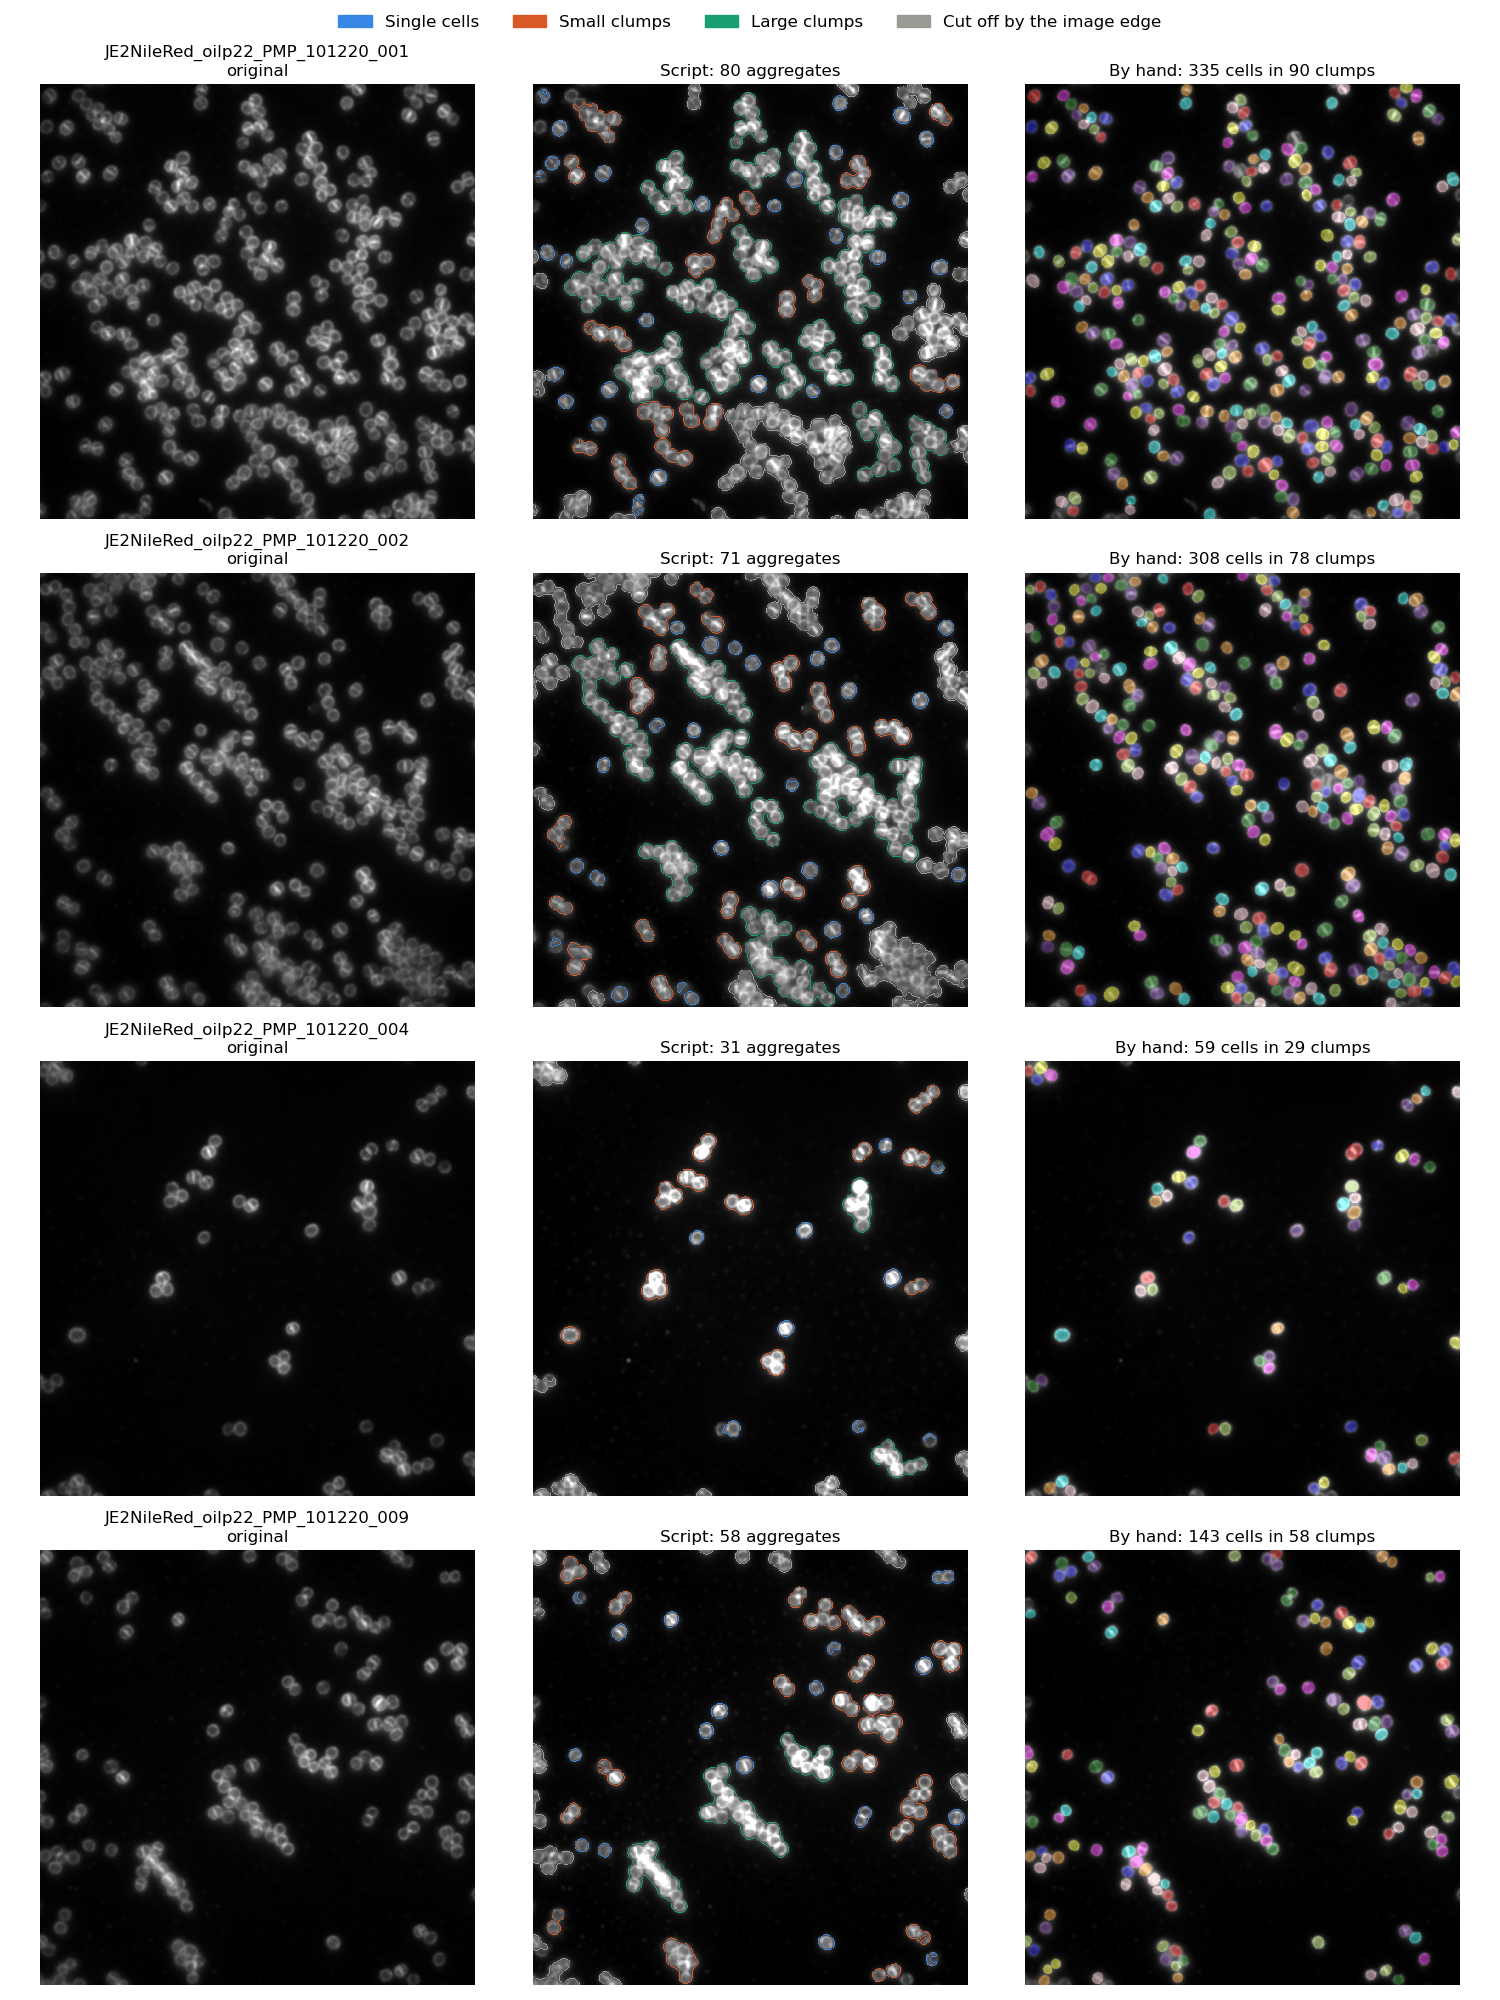

In [13]:
display(Image("results/check/random_sample.png", width=900))

In [14]:
comparison = pd.read_csv("results/check/comparison.csv")
comparison["image"] = comparison["image"].str.replace("JE2NileRed_oilp22_PMP_101220_", "image ")
comparison.round(2)

,image,hand_pixels_found_pct,hand_cells,hand_cells_missed,script_aggregates,hand_clumps,no_hand_cell_at_edge,no_hand_cell_inside,area_ratio_script_to_hand
0,image .tif,97.48,263,9,95,105,5,0,1.59
1,image 001.tif,97.55,335,7,80,90,5,0,1.53
2,image 002.tif,97.08,308,8,71,78,3,0,1.44
3,image 003.tif,99.26,46,0,22,19,2,1,1.64
4,image 004.tif,94.73,59,5,31,29,2,0,1.58
5,image 005.tif,95.92,89,3,51,47,4,0,1.57
6,image 006.tif,99.39,71,1,31,34,1,0,1.63
7,image 007.tif,92.15,89,7,39,35,3,0,1.26
8,image 008.tif,98.04,75,2,29,28,1,0,1.56
9,image 009.tif,96.94,143,5,58,58,3,0,1.52


In [15]:
# Hand-drawn cells inside the aggregates of each size class.
pd.read_csv("results/check/size_class_check.csv")

,size_class,aggregates,median_hand_cells,fewest_hand_cells,most_hand_cells
0,single_cell,221,1.0,0.0,2.0
1,small_clump,195,2.0,1.0,7.0
2,large_clump,47,9.0,5.0,35.0


### What the review found, and what was changed

The first version filled **every** hole inside the bright areas, including background enclosed by a ring of cells inside a clump, so that background was counted as cell. Looking at the random sample showed this. The fix was to fill only holes smaller than one cell (`MAX_HOLE_PX` in `analyze_images.py`).

A second look showed that some of the small holes still being filled are tiny gaps between tightly packed cells rather than cell centres. Comparing with the hand-drawn outlines showed this adds only about 0.3% to the total cell area, and keeping the step means fewer dim cells are left hollow, so it stays.

The review also showed that the few aggregates with no hand-drawn cell are almost all real cells cut off by the image edge, which the person drawing the outlines skipped. These are flagged in the `touches_edge` column.

Reviewing the size classes showed that large clumps are the most likely to be cut off by the image edge, and cut-off clumps are left out of the size shares. The table now reports how much cell area this affects (`pct_cell_area_cut_off`).

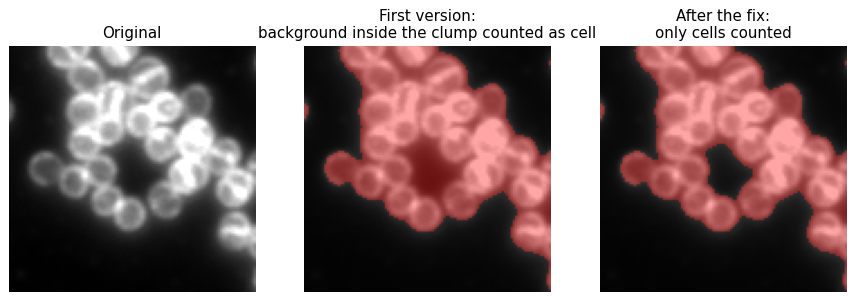

In [16]:
display(Image("docs/fix_before_after.png", width=900))

### Known limits

- The size class cut-offs were chosen using these same 12 images, so other cells need other cut-offs, and the 88% agreement for single cells may be a little optimistic.
- Large clumps can be under-counted: aggregates cut off by the image edge are left out of the size shares. That is 5% to 29% of the cell area per image.
- The workflow's cell area is about 1.5 times the hand-drawn area, because the hand outlines were drawn just inside each membrane while the workflow includes the whole glowing membrane.
- Gaps between tightly packed cells that are smaller than one cell are counted as part of the clump, which adds about 0.3% to the total cell area.
- Very dim, out-of-focus cells are sometimes missed or only partly found (about 3% of cells).
- The workflow counts aggregates, not the individual cells inside each clump.